Mean Anomaly

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

In [3]:
# K = const = sqrt(G*M_SUN)
k = 0.017202098950000 #AU^3/2 days^-1 
#### TABLE 4 ####
#Estimated Values
a_est = 2.947 #AU
omega_est = 80.65 #deg
i_est = 10.56 #deg
e_est = 0.125
w_est = 63.20 #deg
tau_est = 2454833 #Julian Day
################
#True Values
a = 2.766 #AU
omega = 80.72 #deg
i = 10.61 #deg
e = 0.079
w = 73.12 #deg
tau = 2454868 #Julian Day
################

def newton_integrate(k,e,a,tau,dt=0.01):
    # p = period [days]
    # n = mean motion [rad/day]
    # M = mean anomaly [rad]
    # E = eccentric anomaly [rad]
    # t = current epoch [JD]
    # tau = epoch of perihelion [JD]
    # dt = time step [days]

    n = k*a**(-3/2)

    p = (2*np.pi)/n

    # M as a function of E
    def M_E(E):
        return E - e*np.sin(E)
    
    # M as a function of t
    t = np.arange(tau,tau + 1.5*p,dt)
    M = n*(t-tau)

    print(f"Using {len(t)-1} steps with time step {dt}")
    
    # Initialize arrays to store solution. Set E_0 = M for first iteration
    E_values = M.copy()
    M_values = E_values.copy()

    for j in range(1,len(t)):
        M_values[j-1] = M_E(E_values[j-1])
        E_values[j] = E_values[j-1] +(M[j-1] - M_E(E_values[j-1]))/(1-e*np.cos(E_values[j-1]))
    return E_values, M_values, t

#True Orbit
E_true, M_true, t_true = newton_integrate(k, e, a, tau)
#Estimated Orbit
E_est, M_est, t_est = newton_integrate(k, e_est, a_est, tau_est)


Using 252039 steps with time step 0.01
Using 277178 steps with time step 0.01


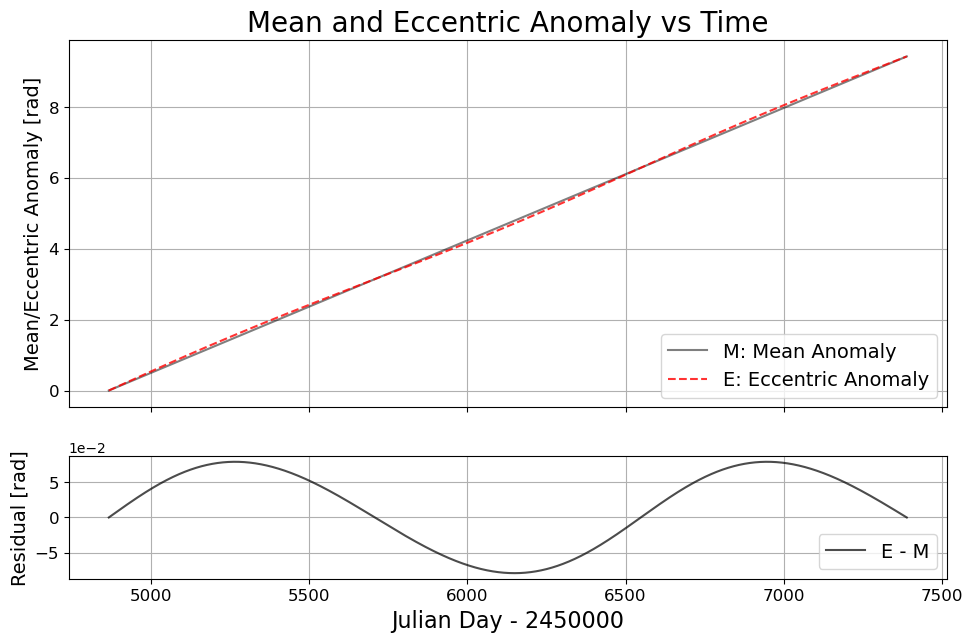

In [4]:
T = t_true - 2450000 
r = a*(1-e*np.cos(E_true)) #eq 22
nu = 2*np.arctan(np.sqrt((1+e)/(1-e))*np.tan(E_true/2)) #eq 31
theta = nu + np.deg2rad(w) #Look above eq 36

T_est = t_est - 2450000 
r_est = a_est*(1-e_est*np.cos(E_est)) #eq 22
nu_est = 2*np.arctan(np.sqrt((1+e_est)/(1-e_est))*np.tan(E_est/2)) #eq 31
theta_est = nu_est + np.deg2rad(w_est) #Look above eq 36

gr = 1.618033988749
scale = 7

f, (a0, a1) = plt.subplots(nrows=2, 
             sharex=True,
             #subplot_kw=dict(frameon=False), 
             figsize = (scale*gr, scale),
             gridspec_kw={'height_ratios': [3, 1]})
#Plot 1
a0.plot(T, M_true, "-", color = 'k', alpha = 0.5, label = 'M: Mean Anomaly')
a0.plot(T, E_true, "--", color = 'r', alpha = 0.8, label = 'E: Eccentric Anomaly')
a0.set_ylabel("Mean/Eccentric Anomaly [rad]", size = 14)
a0.set_title("Mean and Eccentric Anomaly vs Time",size = 20)
a0.legend(loc = 4, prop={'size': 14})
a0.tick_params(axis='y', labelsize=12)
a0.grid()

#Plot 2
a1.plot(T, E_true-M_true, "-", color = 'k', alpha = 0.7, label = 'E - M')
a1.set_xlabel("Julian Day - 2450000", size = 16)
a1.set_ylabel("Residual [rad]", size = 14)
a1.grid()
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
a1.tick_params(axis='x', labelsize=12)
a1.tick_params(axis='y', labelsize=12)
a1.legend(loc = 4,prop={'size': 14})
plt.show()

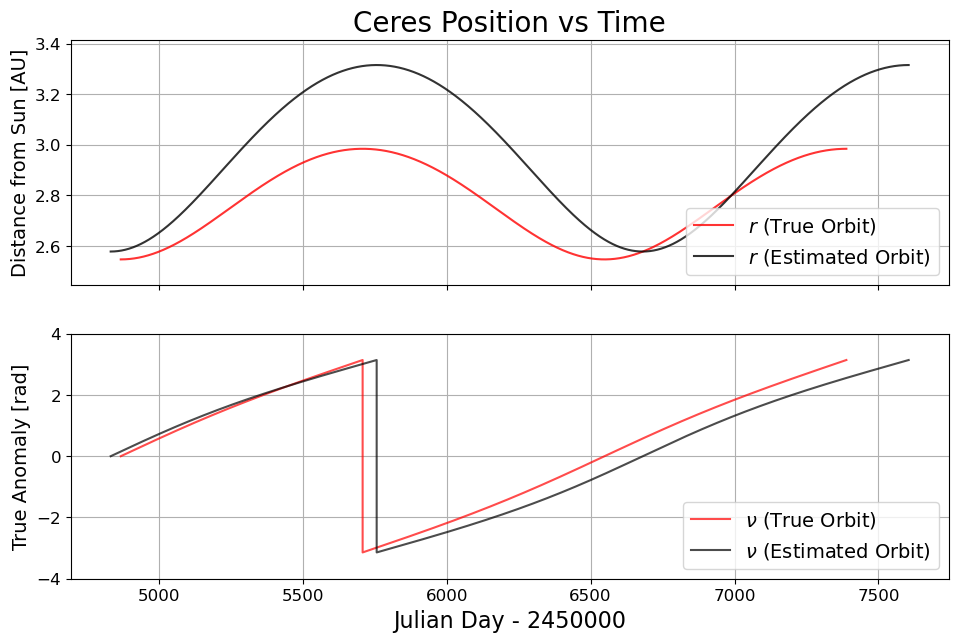

In [5]:
f, (a0, a1) = plt.subplots(nrows=2, 
             sharex=True,
             #subplot_kw=dict(frameon=False), 
             figsize = (scale*gr, scale),
             gridspec_kw={'height_ratios': [1, 1]})
#Plot 1
a0.plot(T, r, color = 'r', alpha = 0.8, label = r"$r$ (True Orbit)")
a0.plot(T_est, r_est, color = 'k', alpha = 0.8, label = r"$r$ (Estimated Orbit)")
a0.set_ylabel("Distance from Sun [AU]", size = 14)
a0.set_title("Ceres Position vs Time",size = 20)
a0.legend(loc = 4, prop={'size': 14})
a0.tick_params(axis='y', labelsize=12)
a0.grid()
a0.set_ylim(np.min(r) - 0.1,np.max(r_est) + 0.1)

#Plot 2
a1.plot(T, nu, "-", color = 'r', alpha = 0.7, label = r'$\nu$ (True Orbit)')
a1.plot(T_est, nu_est, "-", color = 'k', alpha = 0.7, label = r'$\nu$ (Estimated Orbit)')
a1.set_xlabel("Julian Day - 2450000", size = 16)
a1.set_ylabel("True Anomaly [rad]", size = 14)
a1.grid()
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
a1.tick_params(axis='x', labelsize=12)
a1.tick_params(axis='y', labelsize=12)
a1.legend(loc = 4,prop={'size': 14})
a1.set_ylim(-4,4)

plt.show()

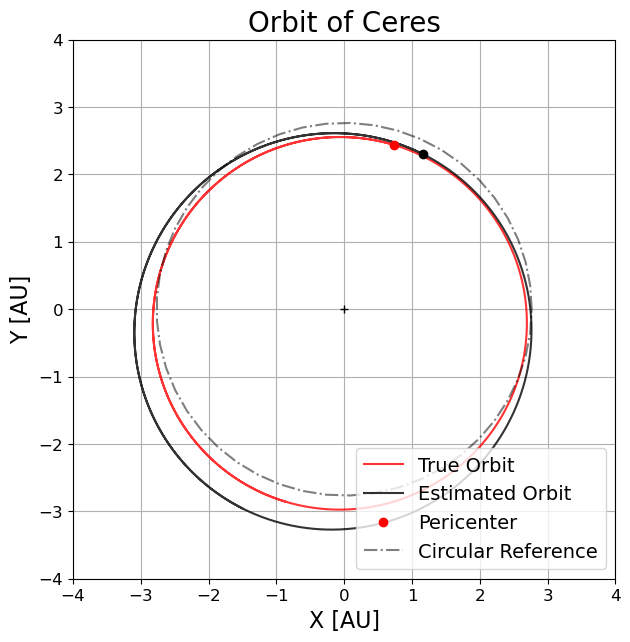

In [6]:
plt.figure(figsize=(scale,scale))

plt.plot(0, 0,'+', color = 'k')

plt.plot(r*np.cos(theta), r*np.sin(theta), color = 'r', alpha = 0.8, label = "True Orbit")

plt.plot(r_est*np.cos(theta_est), r_est*np.sin(theta_est), alpha = 0.8, color = 'k', label = "Estimated Orbit")

plt.plot(r[0]*np.cos(theta[0]), r[0]*np.sin(theta[0]), 'o', color = 'r', label = "Pericenter")
plt.plot(r_est[0]*np.cos(theta_est[0]), r_est[0]*np.sin(theta_est[0]), 'o', color = 'k')

phi = np.linspace(0, 2*np.pi)
plt.plot(a*np.cos(phi), a*np.sin(phi), '-.', color = 'k', alpha = 0.5, label = "Circular Reference")

plt.xlim(-4,4)
plt.ylim(-4,4)
plt.xlabel("X [AU]", size = 16)
plt.ylabel("Y [AU]", size = 16)
plt.grid()
plt.title("Orbit of Ceres", size = 20)
plt.legend(loc = 4,prop={'size': 14})
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.show()

2.5 Ecliptic & Equatorial Coordinates

In [7]:
### Ceres ###
# *******************************************************************************
# Date_________JDUT     R.A.___(ICRF)___DEC     ObsEcLon    ObsEcLat
# ******************************************************************
# $$SOE
# 2454702.500000000     124.86809  23.75270  121.7592660   4.0625672
# 2454703.500000000     125.33031  23.69072  122.1865452   4.0992600
# 2454704.500000000     125.79168  23.62790  122.6133860   4.1361611
# $$EOE
# *******************************************************************************

def celestial_to_ecliptic_cart(ra,dec):
    X_eq = np.cos(np.deg2rad(ra))*np.cos(np.deg2rad(dec))
    Y_eq = np.sin(np.deg2rad(ra))*np.cos(np.deg2rad(dec))
    Z_eq = np.sin(np.deg2rad(dec))
    # print("Ecliptic Cartesian Coordinates (deg): ", np.rad2deg(X_eq),np.rad2deg(Y_eq),np.rad2deg(Z_eq))
    epsilon = np.deg2rad(23.43929111)
    x = X_eq
    y = Y_eq*np.cos(epsilon) + Z_eq*np.sin(epsilon)
    z = -Y_eq*np.sin(epsilon) + Z_eq*np.cos(epsilon)
    # print("Unit Vectors in Ecliptic Frame (rad): ", x,y,z)
    return x,y,z

# Given three times returns velocity at 2nd time
def s_dot(times,coords):
    # using taylor series
    tau_1 = times[1] - times[0]
    tau_3 = times[2] - times[1]
    return (tau_3*(coords[1]-coords[0]))/(tau_1*(tau_1+tau_3)) + (tau_1*(coords[2]-coords[1]))/(tau_3*(tau_1+tau_3))

# Given three times returns acceleration at 2nd time
def s_dot_dot(times,coords):
    tau_1 = times[1] - times[0]
    tau_3 = times[2] - times[1]
    return 2*(coords[2] - coords[1])/(tau_3*(tau_1+tau_3)) - 2*(coords[1]-coords[0])/(tau_1*(tau_1+tau_3))

def rho_solver(r_guess, R, s, s_dot, s_dot_dot, accuracy = 1e-4, max_itr=10**6, inc=0.001):
    def rho(r,R,s,s_dot,s_dot_dot):
        return k**2*(1/np.linalg.norm(R[1])**3 - 1/r**3)*(np.dot(s_dot,np.cross(R[1],s[1])))/(np.dot(s_dot,np.cross(s_dot_dot,s[1])))
    r = r_guess
    dr = inc
    for i in range(0,max_itr):
        rho_old = rho(r, R, s, s_dot, s_dot_dot)
        r+=dr
        rho_new = rho(r, R, s, s_dot, s_dot_dot)
        d_rho = np.abs(rho_new) - np.abs(rho_old)
        if d_rho <= accuracy:
            #print(f"Solved rho({r}) = {rho_new} in {i} iterations, with accuracy {d_rho}")
            return rho_new

def rho_dot(r,R,s,s_dot,s_dot_dot):
    return (k**2/2)*(1/np.linalg.norm(R[1])**3 - 1/np.linalg.norm(r)**3)*(np.dot(s_dot_dot,np.cross(R[1],s[1])))/(np.dot(s_dot_dot,np.cross(s_dot,s[1])))
def r(rho,R,s):
    return np.sqrt(rho**2 + np.linalg.norm(R[1])**2 + 2*rho*np.dot(s[1],R[1]))
def r_dot(rho,rho_dot,R_dot, s, s_dot):
    return R_dot[1] + rho*s_dot + rho_dot*s[1]

######################## Proserpina (Tom's obs and Ephemeris sun-earth vector) ########################
R_pros = np.array([[-4.839943788688217e-01, 8.567315077911066e-01, -2.430059010880054e-05],
                   [-4.993079108676164e-01, 8.480006311211998e-01, -2.466818936373878e-05],
                   [-5.297936568478157e-01, 8.295212676726603e-01, -2.517397903282655e-05],
                   [-5.712949145475025e-01, 8.018594933188263e-01, -2.501185296539947e-05]])

R_dot_pros = np.array([[-1.526643949321232e-02, -8.525858896020743e-03, -3.855835353970162e-07],
                       [-1.511257153420666e-02, -8.794493842540710e-03, -3.374110866457986e-07],
                       [-1.478571027653773e-02, -9.328745251113220e-03, -1.391122123137612e-07],
                       [-1.429468504521881e-02, -1.005377067836366e-02, 2.646232556130592e-07]])

pros_jd = np.array([2455946.811041667, 2455947.819178241, 2455949.858240741, 2455952.711863426])

print("Proserpina")
print("------------------------")

# Get unit vectors from ra, dec
#coords_prop_ra_dec = np.array([[81.029, 26.981],[80.880,26.967],[80.631,26.940],[80.339,26.908]])
coords_prop_ra_dec = np.array([[81.22811, 26.99100], [81.08767, 26.97887], [80.82548, 26.95393], [80.50876, 26.91860]])

s_pros = np.array([celestial_to_ecliptic_cart(*coord) for coord in coords_prop_ra_dec])

# Unit vector derivatives
s_dot_pros = s_dot(pros_jd,s_pros)
s_dot_dot_pros = s_dot_dot(pros_jd,s_pros)

# Solve for rho, rho_dot, r, r_dot
rho_pros = rho_solver(2.5, R_pros, s_pros, s_dot_pros, s_dot_dot_pros)
rho_dot_pros = rho_dot(rho_pros, R_pros, s_pros, s_dot_pros, s_dot_dot_pros)
r_pros = r(rho_pros, R_pros, s_pros)
r_pros_vec = R_pros[1] + rho_pros*s_pros[1]
r_dot_pros = r_dot(rho_pros, rho_dot_pros, R_dot_pros, s_pros, s_dot_pros)


print("s_pros all measurements (1st): ", s_pros[0])
print("s_pros all measurements (2nd): ", s_pros[1])
print("s_pros all measurements (3rd): ", s_pros[2])
print("s_pros all measurements (4th): ", s_pros[3])



print("rho: ", rho_pros)
print("rho_dot:", rho_dot_pros)
print("r: ", r_pros_vec)
print("|r|: ", r_pros)
print("r_dot: ", r_dot_pros)
print("|r_dot|: ", np.linalg.norm(r_dot_pros))
print("s: ", s_pros[0])
print("s_dot: ", s_dot_pros)
print("s_dot_dot: ", s_dot_dot_pros)
print("------------------------")

######################## Ceres ##########################################
R_ceres = np.array([[0.8849747143832394, -0.4888376660952258, 4.464941484204715E-06],
     [0.8928924150493818, -0.4737757563214451, 4.401526303436856E-06],
     [0.9005547316019139, -0.4585763814046491, 4.482870706977596E-06]])

R_dot_ceres = np.array([[8.044450672656130e-03, 1.499181301004085e-02, -1.409324171451239e-07],
         [7.790478517409600e-03, 1.513133074608821e-02, 1.194754466248652e-08],
         [7.533687958968585e-03, 1.526671772306336e-02, 1.469642152045375e-07]])

# Taken from NASA ephemeris apparent ra, dec
ceres_jd = np.array([2454702.5, 2454703.5, 2454704.5])
coords_ceres_ra_dec = np.array([[124.99501, 23.72690], [125.45718,23.66456], [125.91851, 23.60140]])

print("Ceres")
print("----------------------")
s_ceres = np.array([celestial_to_ecliptic_cart(*coord) for coord in coords_ceres_ra_dec])

# Unit vector derivatives solved using taylor series expansions
s_dot_ceres = s_dot(ceres_jd,s_ceres)
s_dot_dot_ceres = s_dot_dot(ceres_jd,s_ceres)

# Solve for rho, rho_dot, r, r_dot
rho_ceres = rho_solver(2.0, R_ceres, s_ceres, s_dot_ceres, s_dot_dot_ceres)
rho_dot_ceres = rho_dot(rho_ceres, R_ceres, s_ceres, s_dot_ceres, s_dot_dot_ceres)
r_ceres = r(rho_ceres, R_ceres, s_ceres)
r_ceres_vec = R_ceres[1] + rho_ceres*s_ceres[1]
r_dot_ceres = r_dot(rho_ceres, rho_dot_ceres, R_dot_ceres, s_ceres, s_dot_ceres)
r_dot_mag_ceres = np.linalg.norm(r_dot_ceres)

print("rho: ", rho_ceres)
print("rho_dot:", rho_dot_ceres)
print("r: ", r_ceres_vec)
print("|r|: ", r_ceres)
print("r_dot: ", r_dot_ceres)
print("|r_dot|: ", r_dot_mag_ceres)
print("s: ", s_ceres[0])
print("s_dot: ", s_dot_ceres)
print("s_dot_dot: ", s_dot_dot_ceres)
print("------------------------")

#### FROM NASA EPHEMERIS TO CHECK VALUES [AU] ###
# rho_ceres = 3.42618221672372
# rho_dot_ceres = -0.0071286699949
# r_dot_ceres = 0.01099817223

# rho_pros = 2.00939831254757
# rho_dot_pros = 0.008192355592398
# r_dot_pros = 0.00982891772884
# r_pros  = 2.84469275723986



Proserpina
------------------------
s_pros all measurements (1st):  [0.13589024 0.9885167  0.06609521]
s_pros all measurements (2nd):  [0.13806332 0.9882207  0.06601792]
s_pros all measurements (3rd):  [0.14212218 0.98765705 0.06583944]
s_pros all measurements (4th):  [0.14703034 0.98695803 0.06554333]
rho:  2.002035489549954
rho_dot: 0.00788279914395846
r:  [-0.22290024  2.82645354  0.13214555]
|r|:  2.8383069959020517
r_dot:  [-0.00981806 -0.00158098  0.00035938]
|r_dot|:  0.00995102410217234
s:  [0.13589024 0.9885167  0.06609521]
s_dot:  [ 2.10095687e-03 -2.87924325e-04 -8.02641200e-05]
s_dot_dot:  [-1.08290903e-04  1.12790162e-05 -7.12670452e-06]
------------------------
Ceres
----------------------
rho:  3.4441201544214493
rho_dot: -0.007501539330260613
r:  [-0.93701971  2.43358552  0.24624747]
|r|:  2.619347675968421
r_dot:  [-0.00980976 -0.00497413  0.00166948]
|r_dot|:  0.011124767385878927
s:  [-0.52502888  0.84812959  0.07085812]
s_dot:  [-0.00626747 -0.003999    0.00064045]


Orbital Element Calculations

In [8]:
### Semi Major Axis ###
def a(r, r_dot):
    return (k**2*r) / (2*k**2 - r*np.dot(r_dot,r_dot))

### Specific Angular Momentum ###
def h(r, r_dot):
    return np.cross(r,r_dot)

### Longitude of Ascending Node (deg) ###
def big_omega(h):
    return np.arctan2(h[0],-h[1])

### Inclination ###
def inc(h):
    return np.arccos(h[2]/np.linalg.norm(h))

### Eccentricity ###
def e(h,a):
    return np.sqrt(1 - np.linalg.norm(h)**2/(k**2*a))

### Eccentric Anomaly ###
def E(a,r,r_dot,e):
    theta = np.arccos(r[2]/np.linalg.norm(r))
    phi = np.arctan2(r[1],r[0])
    e_r = np.array([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)])
    v_r = np.dot(r_dot, e_r)
    return np.arccos((a-np.linalg.norm(r))/(a*e))*np.sign(v_r)

### Mean Anomaly ###
def M(E, e):
    return E - e*np.sin(E)

### True Anomaly ###
def nu(e,E):
    return 2 * np.arctan(np.sqrt((1+e)/(1-e))*np.tan(E/2))

### Argument of Perihelion ###
def little_omega(nu,x,y,r,big_omega):
    nu_plus_omega = np.arccos((x*np.cos(big_omega) + y*np.sin(big_omega))/r)
    return nu_plus_omega - nu

### Epoch of perihelion ###
def tau(a,t,M):
    n = k*a**(-3/2)
    return t - M/n

def elements(r, r_dot, t):
    a_val = a(np.linalg.norm(r), r_dot)
    h_val = h(r, r_dot)
    big_omega_val = big_omega(h_val)
    i_val = inc(h_val)
    e_val = e(h_val,a_val)
    E_val = E(a_val,r,r_dot,e_val)
    M_val = M(E_val,e_val)
    nu_val = nu(e_val,E_val)
    little_omega_val = little_omega(nu_val,r[0],r[1],np.linalg.norm(r),big_omega_val)
    tau_val = tau(a_val,t,M_val)
    print("Orbital Elements")
    print("------------------------")
    print("a [AU]: ", a_val)
    #print("h: ", h_val)
    print("Big Omega: ", np.rad2deg(big_omega_val))
    print("i [deg]: ", np.rad2deg(i_val))
    print("e: ", e_val)
    #print("E [deg]: ", np.rad2deg(E_val))
    #print("nu [deg]: ", np.rad2deg(nu_val))
    print("Little Omega [deg]: ", np.rad2deg(little_omega_val))
    print("tau: ", tau_val)
    #print("M [deg]: ", np.rad2deg(M_val))
    print("------------------------")
    
    elements = [a_val, big_omega_val, i_val, e_val, little_omega_val, tau_val, nu_val, M_val]
    return elements
    
print("Ceres")
ceres_elements = elements(r_ceres_vec, r_dot_ceres, ceres_jd[1])

print("26 Proserpina")
pros_elements = elements(r_pros_vec, r_dot_pros, pros_jd[1])


Ceres
Orbital Elements
------------------------
a [AU]:  2.8959048393998703
Big Omega:  80.8541445462403
i [deg]:  10.630716542955822
e:  0.12815952225288468
Little Omega [deg]:  77.625986623931
tau:  2454888.151932441
------------------------
26 Proserpina
Orbital Elements
------------------------
a [AU]:  2.70263403281854
Big Omega:  45.173038181860505
i [deg]:  3.5160900257107226
e:  0.09355703534558923
Little Omega [deg]:  176.2600894013205
tau:  2456479.4267678214
------------------------


Predict Asteroid Position

Using 270001 steps with time step 0.01
Using 243428 steps with time step 0.01


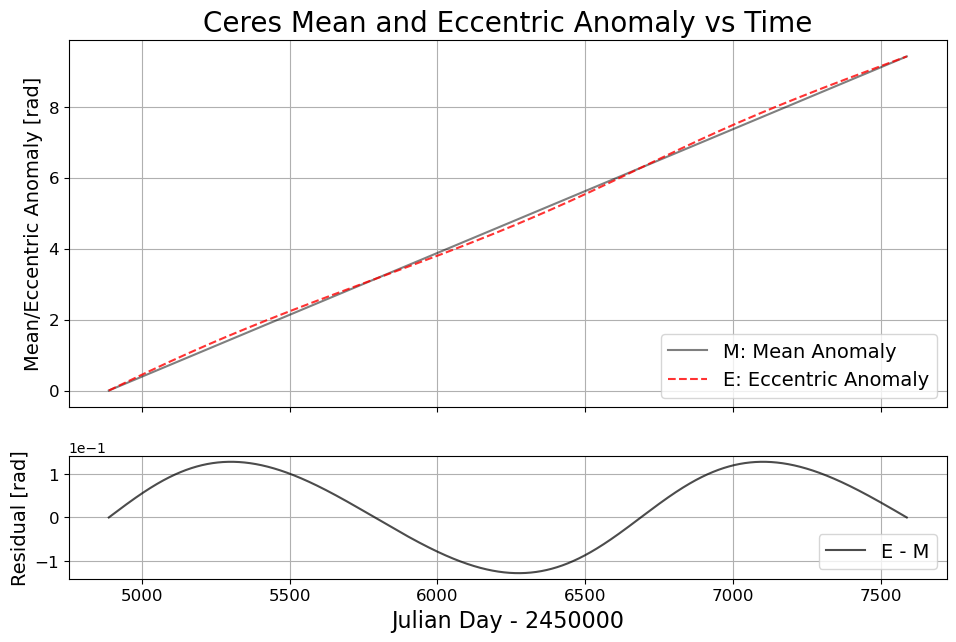

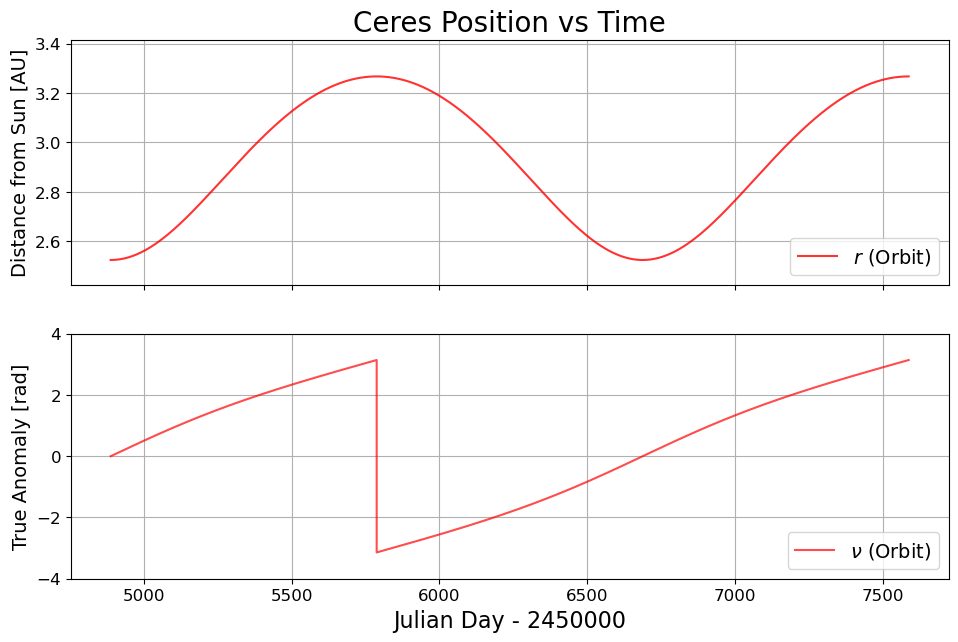

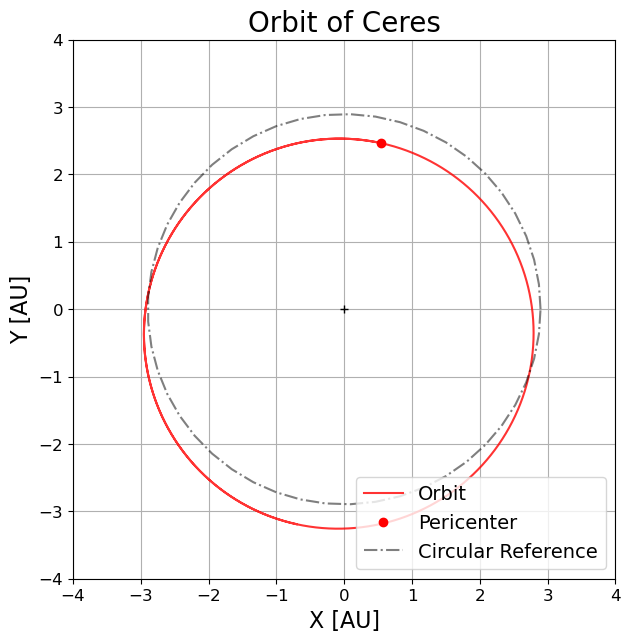

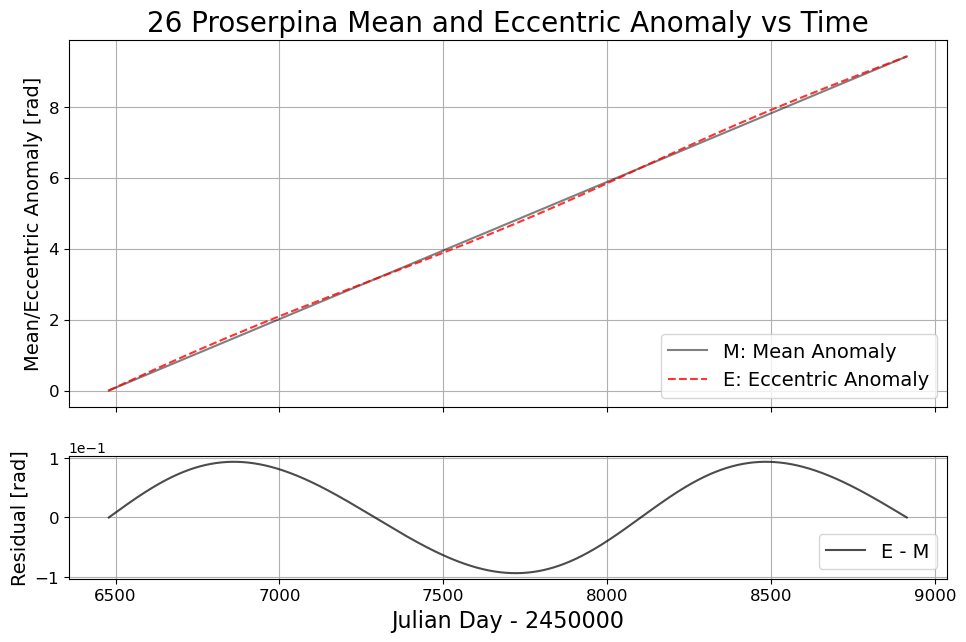

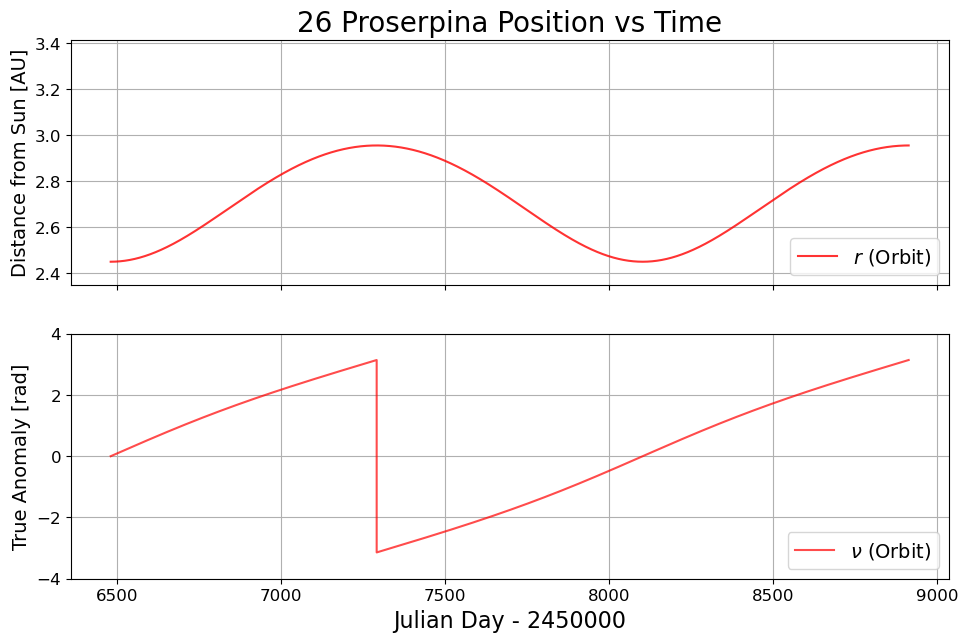

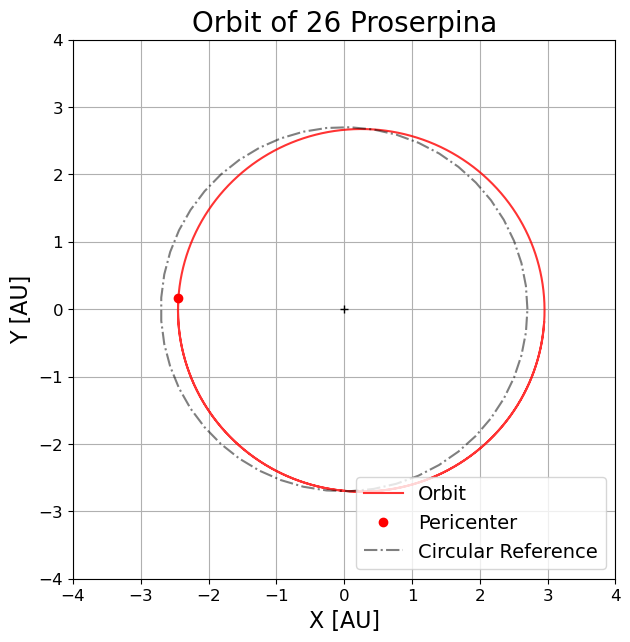

In [9]:
### Ceres ###
a_ceres = ceres_elements[0]
big_omega_ceres = ceres_elements[1]
i_ceres = ceres_elements[2]
e_ceres = ceres_elements[3]
little_omega_ceres = ceres_elements[4]
tau_ceres = ceres_elements[5]
M_ceres = ceres_elements[7]

### Proserpina ###
a_pros = pros_elements[0]
big_omega_pros = pros_elements[1]
i_pros = pros_elements[2]
e_pros = pros_elements[3]
little_omega_pros = pros_elements[4]
tau_pros = pros_elements[5]
M_pros = pros_elements[7]

E_ceres, M_ceres, T_ceres = newton_integrate(k, e_ceres, a_ceres, tau_ceres)
E_pros, M_pros, T_pros = newton_integrate(k, e_pros, a_pros, tau_pros)
nu_ceres = nu(e_ceres,E_ceres)
nu_proserpina = nu(e_pros,E_pros)

def orbit(T, a, E, e, w, nu, M, object_name):
        T = T - 2450000 
        r = a*(1-e*np.cos(E)) #eq 22
        theta = nu + w #Look above eq 36

        gr = 1.618033988749
        scale = 7

        f, (a0, a1) = plt.subplots(nrows=2, 
                sharex=True,
                #subplot_kw=dict(frameon=False), 
                figsize = (scale*gr, scale),
                gridspec_kw={'height_ratios': [3, 1]})

        #Plot 1
        a0.plot(T, M, "-", color = 'k', alpha = 0.5, label = 'M: Mean Anomaly')
        a0.plot(T, E, "--", color = 'r', alpha = 0.8, label = 'E: Eccentric Anomaly')
        a0.set_ylabel("Mean/Eccentric Anomaly [rad]", size = 14)
        a0.set_title(f"{object_name} Mean and Eccentric Anomaly vs Time",size = 20)
        a0.legend(loc = 4, prop={'size': 14})
        a0.tick_params(axis='y', labelsize=12)
        a0.grid()

        #Plot 2
        a1.plot(T, E-M, "-", color = 'k', alpha = 0.7, label = 'E - M')
        a1.set_xlabel("Julian Day - 2450000", size = 16)
        a1.set_ylabel("Residual [rad]", size = 14)
        a1.grid()
        plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
        a1.tick_params(axis='x', labelsize=12)
        a1.tick_params(axis='y', labelsize=12)
        a1.legend(loc = 4,prop={'size': 14})
        plt.show()

        f, (a0, a1) = plt.subplots(nrows=2, 
                sharex=True,
                #subplot_kw=dict(frameon=False), 
                figsize = (scale*gr, scale),
                gridspec_kw={'height_ratios': [1, 1]})

        #Plot 1
        a0.plot(T, r, color = 'r', alpha = 0.8, label = r"$r$ (Orbit)")
        a0.set_ylabel("Distance from Sun [AU]", size = 14)
        a0.set_title(f"{object_name} Position vs Time",size = 20)
        a0.legend(loc = 4, prop={'size': 14})
        a0.tick_params(axis='y', labelsize=12)
        a0.grid()
        a0.set_ylim(np.min(r) - 0.1,np.max(r_est) + 0.1)

        #Plot 2
        a1.plot(T, nu, "-", color = 'r', alpha = 0.7, label = r'$\nu$ (Orbit)')
        a1.set_xlabel("Julian Day - 2450000", size = 16)
        a1.set_ylabel("True Anomaly [rad]", size = 14)
        a1.grid()
        plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
        a1.tick_params(axis='x', labelsize=12)
        a1.tick_params(axis='y', labelsize=12)
        a1.legend(loc = 4,prop={'size': 14})
        a1.set_ylim(-4,4)

        plt.show()

        plt.figure(figsize=(scale,scale))

        plt.plot(0, 0,'+', color = 'k')

        plt.plot(r*np.cos(theta), r*np.sin(theta), color = 'r', alpha = 0.8, label = "Orbit")

        plt.plot(r[0]*np.cos(theta[0]), r[0]*np.sin(theta[0]), 'o', color = 'r', label = "Pericenter")
        phi = np.linspace(0, 2*np.pi)
        plt.plot(a*np.cos(phi), a*np.sin(phi), '-.', color = 'k', alpha = 0.5, label = "Circular Reference")

        plt.xlim(-4,4)
        plt.ylim(-4,4)
        plt.xlabel("X [AU]", size = 16)
        plt.ylabel("Y [AU]", size = 16)
        plt.grid()
        plt.title(f"Orbit of {object_name}", size = 20)
        plt.legend(loc = 4,prop={'size': 14})
        plt.xticks(fontsize = 12)
        plt.yticks(fontsize = 12)
        plt.show()
        return r*np.cos(theta), r*np.sin(theta), theta, T
        
_, _,_,_ = orbit(T_ceres, a_ceres, E_ceres, e_ceres, little_omega_ceres, nu_ceres, M_ceres, "Ceres")
x_int_pros, y_int_pros, theta_int_pros, T_pros= orbit(T_pros, a_pros, E_pros, e_pros, little_omega_pros, nu_proserpina, M_pros, "26 Proserpina")

Predicting 4th epoch in RA DEC

Predicted RA:  [79.99400686373306, 80.20855312923558, 80.64242804755845, 81.24976703611503]
Predicted Dec:  [25.18260056834619, 25.205654063853395, 25.25130264530193, 25.31301650630416]
Julian Dates of Observations:  [5890.311041667126, 5891.319178240839, 5893.358240740839, 5896.211863426026]


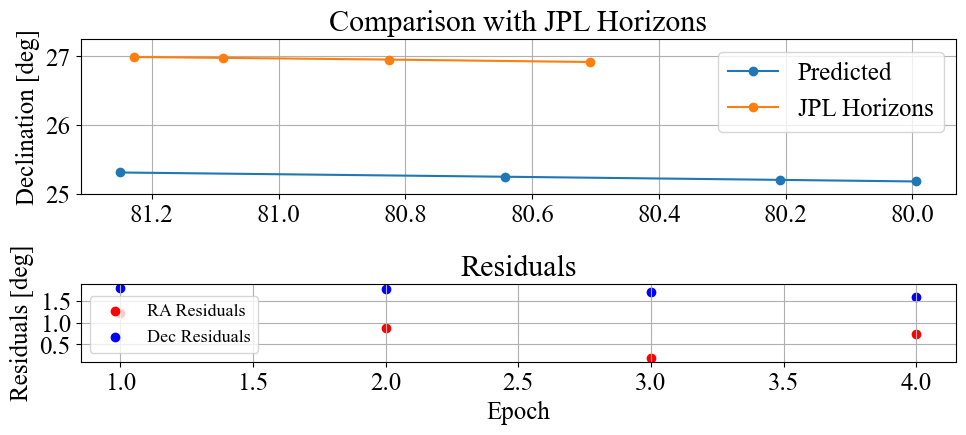

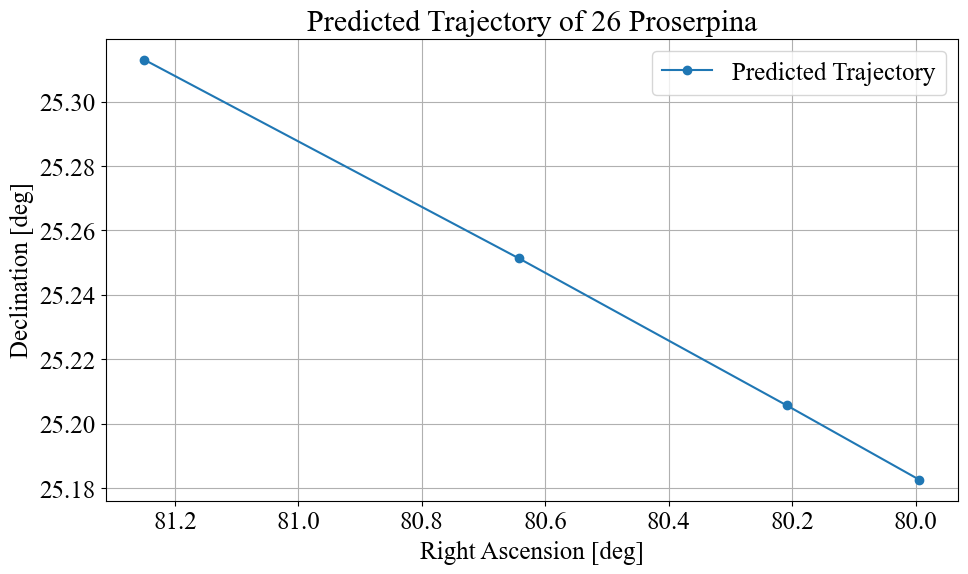

In [20]:
def orbit_to_ec(r,theta,big_omega,i):
    r = np.linalg.norm(r)
    x_ec = r*(np.cos(big_omega)*np.cos(theta) - np.sin(big_omega)*np.sin(theta)*np.cos(i))
    y_ec = r*(np.sin(big_omega)*np.cos(theta) + np.cos(big_omega)*np.sin(theta)*np.cos(i))
    z_ec = r*np.sin(theta)*np.sin(i)
    return x_ec, y_ec, z_ec
    
def eq_cellestial(x, y, z):    
    ra = np.arctan2(y, x)
    ra = np.rad2deg(ra) % 360  # convert to degrees and wrap around to 0-360
    dec = np.arcsin(z/np.linalg.norm([x,y,z]))
    return ra, np.rad2deg(dec)

def eccliptic_to_equatorial(x,y,z):
    epsilon = np.deg2rad(23.43929111)
    x_eq = x
    y_eq = y*np.cos(epsilon) - z*np.sin(epsilon)
    z_eq = y*np.sin(epsilon) + z*np.cos(epsilon)
    return x_eq, y_eq, z_eq

def get_prediction(day):
    epoch_jd = pros_jd[day] - 2450000 - 56.5
    R_jd = R_pros[day]

    jd_index = (np.abs(T - epoch_jd)).argmin() 

    x_predicted_pros = x_int_pros[jd_index]
    y_predicted_pros = y_int_pros[jd_index]
    theta_predicted_pros = theta_int_pros[jd_index]

    predicted_ec = orbit_to_ec([x_predicted_pros,y_predicted_pros], theta_predicted_pros, big_omega_pros, i_pros)
    predicted_eq = eccliptic_to_equatorial(*predicted_ec)
    predicted_celestial = eq_cellestial(*predicted_eq)
    return predicted_celestial, epoch_jd


nasa_ra = [81.228109163,81.087672035,80.825483064,80.508761066]
nasa_dec = [26.991003853, 26.978866941, 26.953925011, 26.918595843]

ra_residual = [np.abs(nasa_ra[i] - get_prediction(i)[0][0]) for i in range(0,4)]
dec_residual = [np.abs(nasa_dec[i] - get_prediction(i)[0][1]) for i in range(0,4)]

predictions = [get_prediction(i) for i in range(0,4)]
prediction_ra = [p[0][0] for p in predictions]
prediction_dec = [p[0][1] for p in predictions]
predictions_jd = [p[1] for p in predictions]

print("Predicted RA: ", prediction_ra)
print("Predicted Dec: ", prediction_dec)
print("Julian Dates of Observations: ", predictions_jd)

import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(10,5))
gs = gridspec.GridSpec(3, 1, height_ratios=[2, 1, 0.05]) 
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])

#xlim = [26.4,278.5]
ylim = [25,27.25]
        
ax1.set_ylim(ylim)
# ax1.set_xlim(xlim)
# ax2.set_xlim(xlim)

ax1.plot(prediction_ra, prediction_dec, 'o-', label = "Predicted")
ax1.plot(nasa_ra, nasa_dec, 'o-', label = "JPL Horizons")
ax1.invert_xaxis()
ax1.set_title("Comparison with JPL Horizons")
ax1.set_ylabel("Declination [deg]")
ax1.grid()
ax1.legend()

# Residual
ax2.scatter(range(1,5), ra_residual, label = "RA Residuals", color='r')
ax2.scatter(range(1,5), dec_residual, label = "Dec Residuals", color='b')
ax2.set_title("Residuals")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Residuals [deg]")
ax2.grid()
ax2.legend(loc='lower left', fontsize=13)

plt.tight_layout()
plt.show()

# Plot only simulation
fig = plt.figure(figsize=(11,6))
plt.title("Predicted Trajectory of 26 Proserpina")
plt.plot(prediction_ra, prediction_dec, 'o-', label = "Predicted Trajectory")
plt.gca().invert_xaxis()
plt.xlabel("Right Ascension [deg]")
plt.ylabel("Declination [deg]")
plt.grid()
plt.legend()
plt.show()




Monte Carlo????

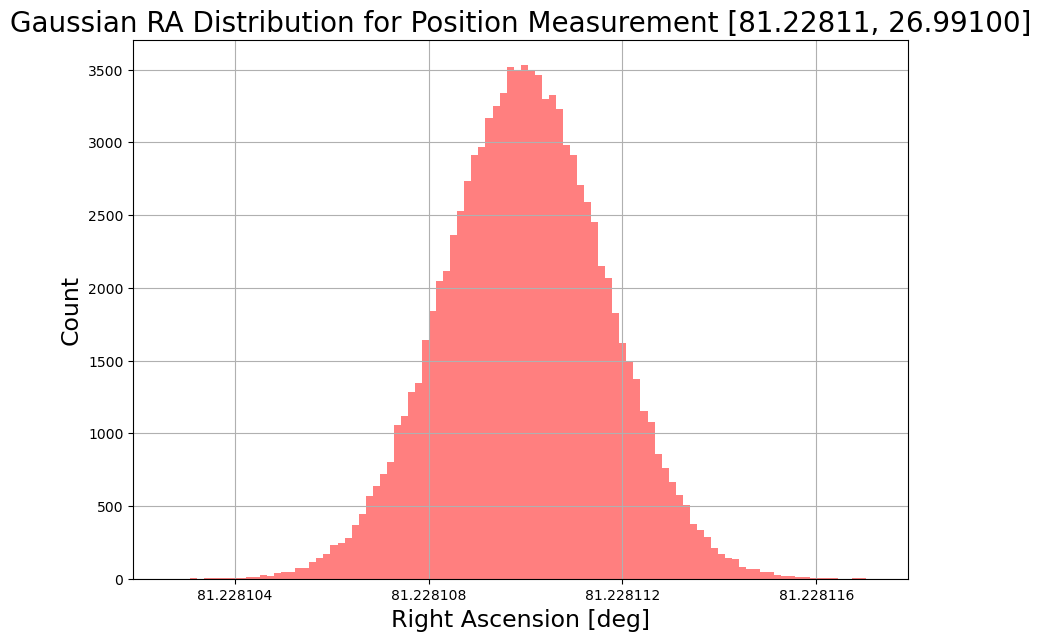

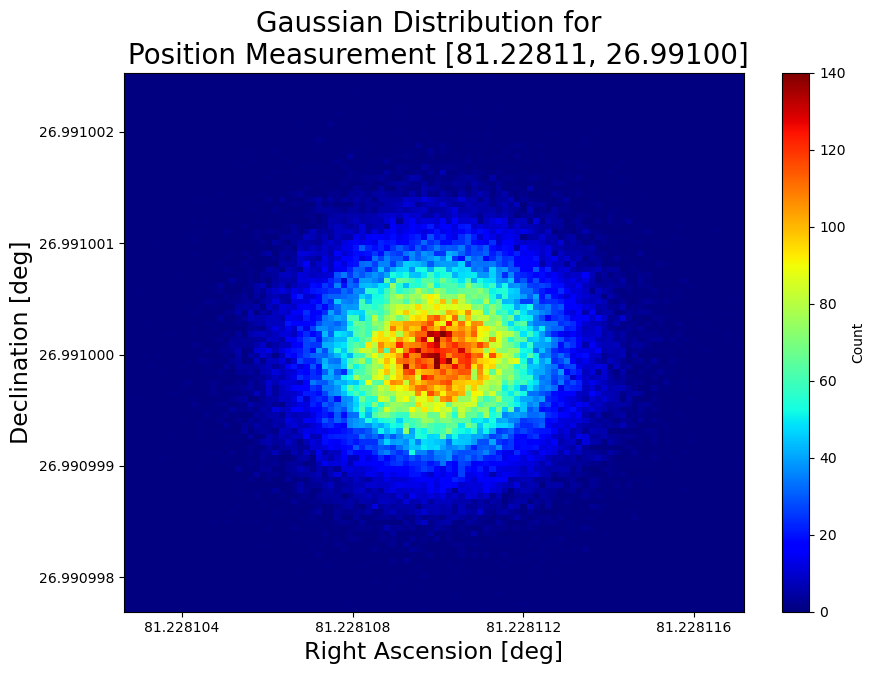

In [11]:
# *******************************************************************************
#  Date__(UT)__HR:MN:SC.fff     R.A.__(airless-appar)__DEC.  RA_3sigma DEC_3sigma
# *******************************************************************************
# $$SOE
#  2012-Jan-20 07:27:54.000      81.228109163  26.991003853      0.006      0.002
#  2012-Jan-21 07:39:37.000      81.087672035  26.978866941      0.006      0.002
#  2012-Jan-23 08:35:52.000      80.825483064  26.953925011      0.006      0.002
#  2012-Jan-26 05:05:05.000      80.508761066  26.918595843      0.006      0.002
# $$EOE
# *******************************************************************************


R_pros = np.array([[-4.839943788688217e-01, 8.567315077911066e-01, -2.430059010880054e-05],
                   [-4.993079108676164e-01, 8.480006311211998e-01, -2.466818936373878e-05],
                   [-5.297936568478157e-01, 8.295212676726603e-01, -2.517397903282655e-05],
                   [-5.712949145475025e-01, 8.018594933188263e-01, -2.501185296539947e-05]])

R_dot_pros = np.array([[-1.526643949321232e-02, -8.525858896020743e-03, -3.855835353970162e-07],
                       [-1.511257153420666e-02, -8.794493842540710e-03, -3.374110866457986e-07],
                       [-1.478571027653773e-02, -9.328745251113220e-03, -1.391122123137612e-07],
                       [-1.429468504521881e-02, -1.005377067836366e-02, 2.646232556130592e-07]])

pros_jd = np.array([2455946.811041667, 2455947.819178241, 2455949.858240741, 2455952.711863426])
coords_pros_ra_dec = np.array([[81.22811, 26.99100], [81.08767, 26.97887], [80.82548, 26.95393], [80.50876, 26.91860]])

# Full routine for Proserpina monte carlo simulation with varying coordinates
def proserpina(coords):
    s_pros = np.array([celestial_to_ecliptic_cart(*coord) for coord in coords])

    # Unit vector derivatives
    s_dot_pros = s_dot(pros_jd,s_pros)
    s_dot_dot_pros = s_dot_dot(pros_jd,s_pros)

    # Solve for rho, rho_dot, r, r_dot
    rho_pros = rho_solver(2.5, R_pros, s_pros, s_dot_pros, s_dot_dot_pros)
    rho_dot_pros = rho_dot(rho_pros, R_pros, s_pros, s_dot_pros, s_dot_dot_pros)
    r_pros = r(rho_pros, R_pros, s_pros)
    r_pros_vec = R_pros[1] + rho_pros*s_pros[1]
    r_dot_pros = r_dot(rho_pros, rho_dot_pros, R_dot_pros, s_pros, s_dot_pros)

    # print("------------------------")
    # print("rho: ", rho_pros)
    # print("rho_dot:", rho_dot_pros)
    # print("r: ", r_pros_vec)
    # print("|r|: ", r_pros)
    # print("r_dot: ", r_dot_pros)
    # print("|r_dot|: ", np.linalg.norm(r_dot_pros))
    # print("s: ", s_pros[0])
    # print("s_dot: ", s_dot_pros)
    # print("s_dot_dot: ", s_dot_dot_pros)
    # print("------------------------")
    
    # Orbital Elements
    return elements(r_pros_vec, r_dot_pros, pros_jd[1])
# Monte Carlo Simulation
ra_3sigma = 0.006 / 3600 # arcsec to deg
dec_3sigma = 0.002 / 3600 # arcsec to deg

from matplotlib.ticker import MaxNLocator
num_samples = 100000
# Generate two gaussians per coordinate with 3 sigma values
ra_1_distribution = np.random.normal(coords_pros_ra_dec[0][0], ra_3sigma, num_samples)
dec_1_distribution = np.random.normal(coords_pros_ra_dec[0][1], dec_3sigma, num_samples)

ra_2_distribution = np.random.normal(coords_pros_ra_dec[1][0], ra_3sigma, num_samples)
dec_2_distribution = np.random.normal(coords_pros_ra_dec[1][1], dec_3sigma, num_samples)

ra_3_distribution = np.random.normal(coords_pros_ra_dec[2][0], ra_3sigma, num_samples)
dec_3_distribution = np.random.normal(coords_pros_ra_dec[2][1], dec_3sigma, num_samples)

fig = plt.figure(figsize=(10, 7))
plt.title("Gaussian RA Distribution for Position Measurement [81.22811, 26.99100]", fontsize=20)
plt.hist(ra_1_distribution, bins=100, color='r', alpha=0.5, label='RA 1')
ax = plt.gca()
ax.ticklabel_format(style='sci', axis='both', useOffset=False)
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
plt.xlabel('Right Ascension [deg]', fontsize=17)
plt.ylabel('Count', fontsize=17)
plt.grid()
plt.show()


# Visualize first coordinate distribution
fig = plt.figure(figsize=(10, 7))
plt.hist2d(ra_1_distribution, dec_1_distribution, bins=100, cmap=plt.cm.jet)
ax = plt.gca()
ax.ticklabel_format(style='sci', axis='both', useOffset=False)
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
plt.colorbar(label='Count')
plt.xlabel('Right Ascension [deg]', fontsize=17)
plt.ylabel('Declination [deg]', fontsize=17)
plt.title('Gaussian Distribution for \n Position Measurement [81.22811, 26.99100]', fontsize=20)
plt.show()

In [12]:
# Simulate!

import pandas as pd

# df = pd.DataFrame(columns=['a', 'big_omega', 'i', 'e', 'little_omega', 'tau', 'nu', 'M'])
# for i in range(0,num_samples):
#     print(f"Sample {i+1}/{num_samples}")
#     ra1_sample = np.random.choice(ra_1_distribution)
#     ra2_sample = np.random.choice(ra_2_distribution)
#     ra3_sample = np.random.choice(ra_3_distribution)
#     dec1_sample = np.random.choice(dec_1_distribution)
#     dec2_sample = np.random.choice(dec_2_distribution)
#     dec3_sample = np.random.choice(dec_3_distribution)
#     coords = np.array([[ra1_sample, dec1_sample], [ra2_sample, dec2_sample], [ra3_sample, dec3_sample]])
#     df.loc[i] = proserpina(coords)
# df.to_csv('proserpina_monte_carlo.csv', index=False)

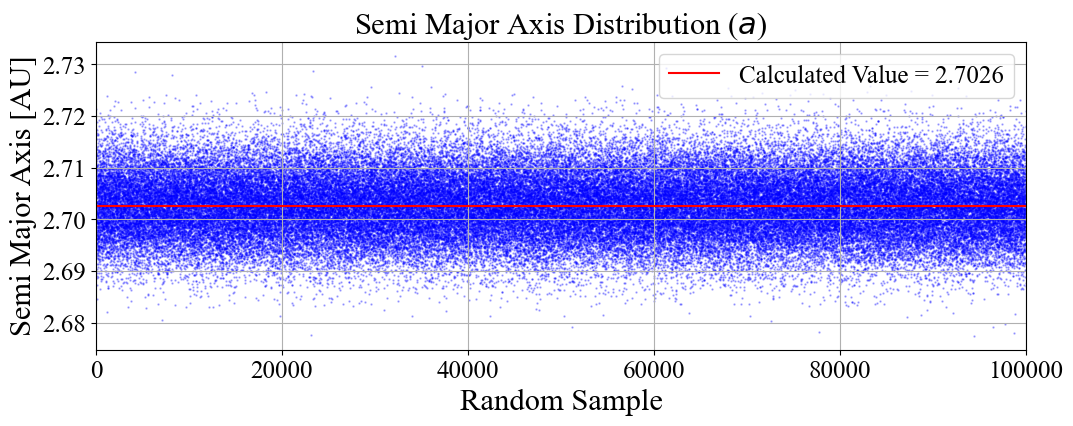

Standard Deviation of Semi Major Axis:  0.006060794489634051
Standard Deviation of Eccentricity:  0.002444734045504142
Standard Deviation of Inclination:  0.00012497587453817936
Standard Deviation of Longitude of Ascending Node:  0.0018052054813478939
Standard Deviation of Argument of Perihelion:  0.04963311762962118
Standard Deviation of Epoch of Perihelion Passage:  14.07612156896299
Semi Major Axis:  2.7026 +/- 0.0061
Eccentricity:  0.0936 +/- 0.0024
Inclination:  3.5161 +/- 0.0072
Longitude of Ascending Node:  45.173 +/- 0.1034
Argument of Perihelion:  176.2601 +/- 2.8438
Epoch of Perihelion Passage:  2456479.4268 +/- 14.0761


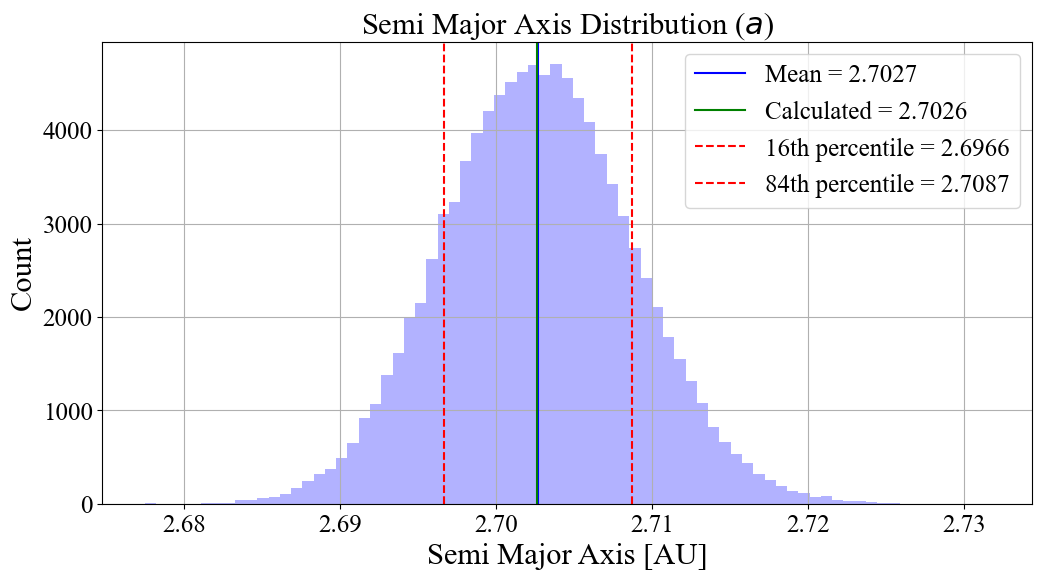

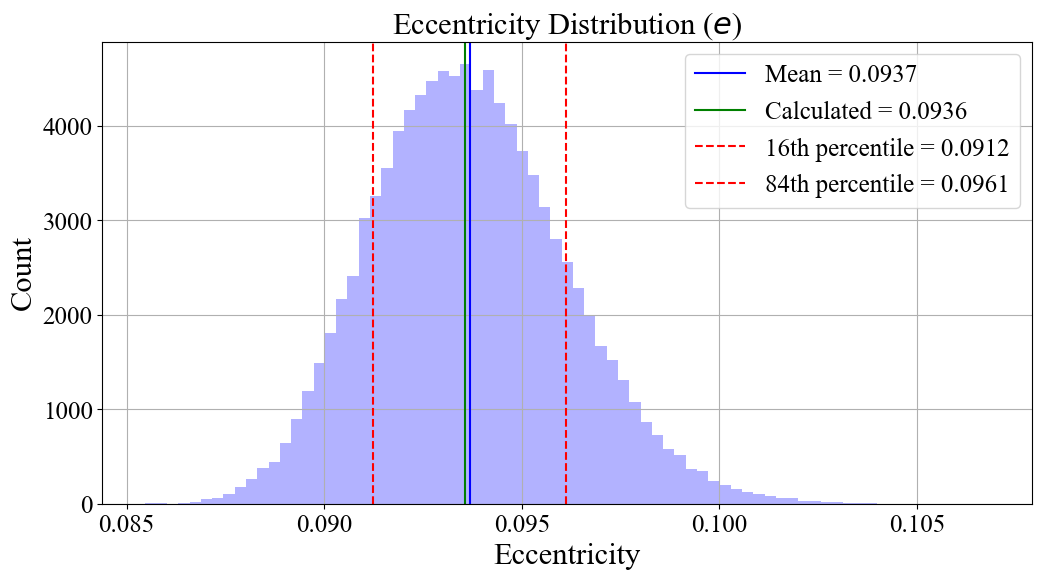

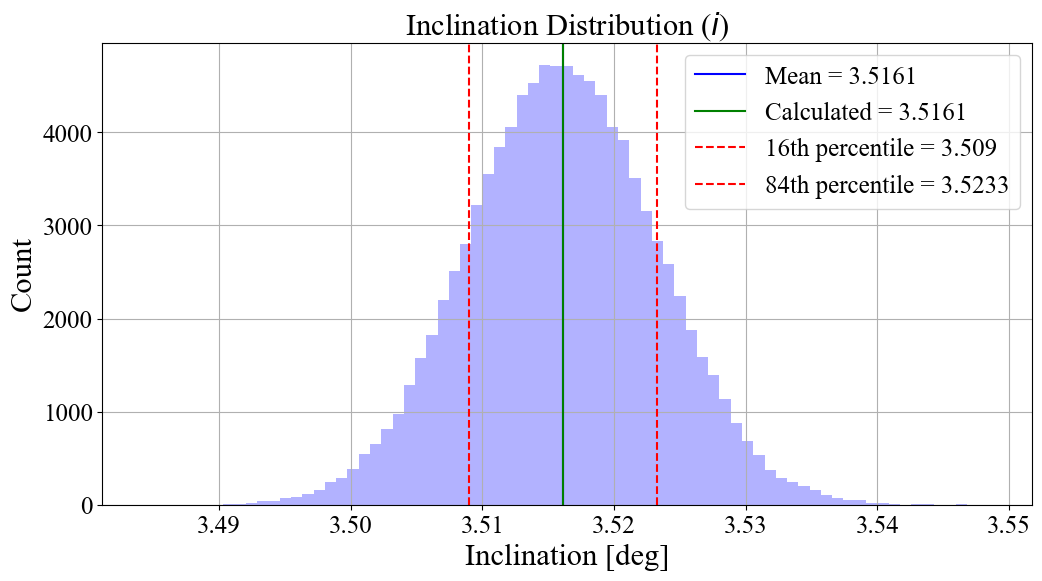

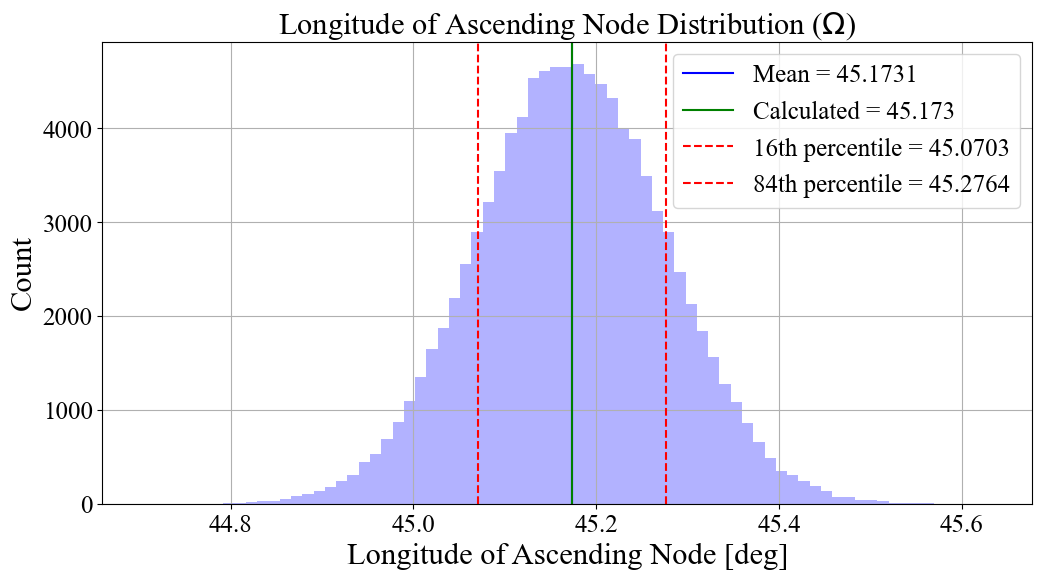

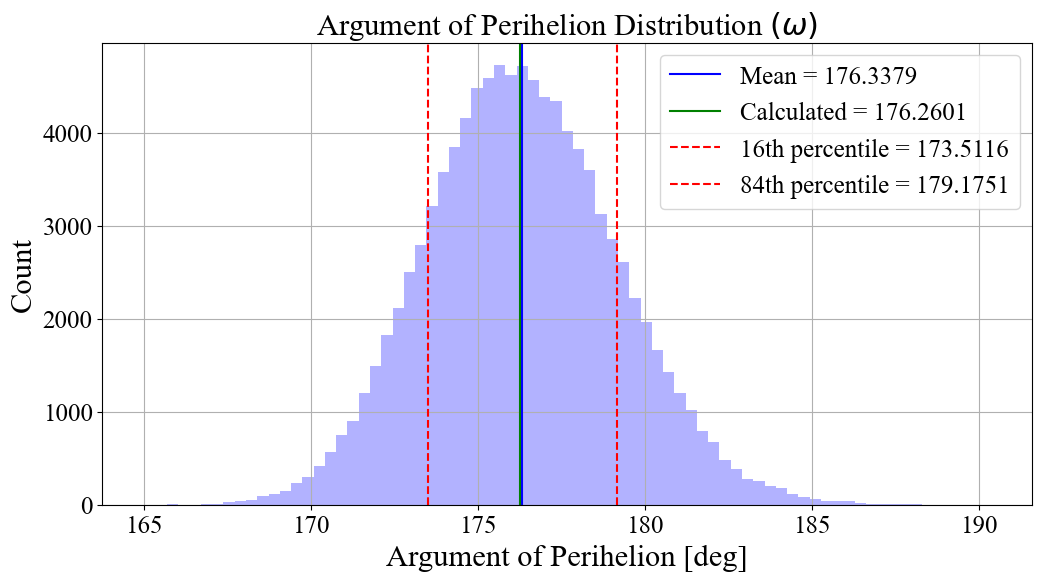

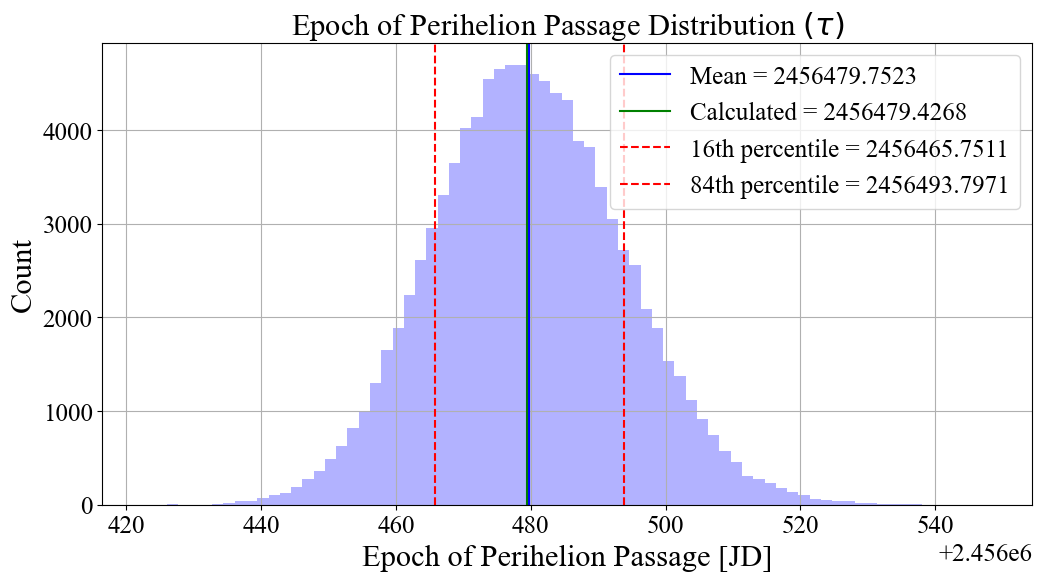

In [18]:
simulated_elements = pd.read_csv('proserpina_monte_carlo.csv')
simulated_elements.describe()

plt.rcParams.update({'font.size': 18})
plt.rcParams.update({'font.family': 'times new roman'})

fig = plt.figure(figsize=(12, 4))
plt.scatter(np.arange(0,num_samples),simulated_elements['a'], color='b', alpha=0.3, s=0.5)
plt.axhline(pros_elements[0], color='r', label=f'Calculated Value = {np.round(pros_elements[0],4)}')
plt.xlabel("Random Sample", fontsize=22)
plt.xlim(0,num_samples)
plt.ylabel("Semi Major Axis [AU]", fontsize=22)
plt.title("Semi Major Axis Distribution ($a$)", fontsize=22)
plt.grid()
plt.legend()
plt.show()




#Print standard deviation of each parameter 
print("Standard Deviation of Semi Major Axis: ", np.std(simulated_elements['a']))
print("Standard Deviation of Eccentricity: ", np.std(simulated_elements['e']))
print("Standard Deviation of Inclination: ", np.std(simulated_elements['i']))
print("Standard Deviation of Longitude of Ascending Node: ", np.std(simulated_elements['big_omega']))
print("Standard Deviation of Argument of Perihelion: ", np.std(simulated_elements['little_omega']))
print("Standard Deviation of Epoch of Perihelion Passage: ", np.std(simulated_elements['tau']))

# Print each orbital parameters value plus or minus 1 sigma 
print("Semi Major Axis: ", np.round(pros_elements[0],4), "+/-", np.round(np.std(simulated_elements['a']),4))
print("Eccentricity: ", np.round(pros_elements[3],4), "+/-", np.round(np.std(simulated_elements['e']),4))
print("Inclination: ", np.round(np.rad2deg(pros_elements[2]),4), "+/-", np.round(np.rad2deg(np.std(simulated_elements['i'])),4))
print("Longitude of Ascending Node: ", np.round(np.rad2deg(pros_elements[1]),4), "+/-", np.round(np.rad2deg(np.std(simulated_elements['big_omega'])),4))
print("Argument of Perihelion: ", np.round(np.rad2deg(pros_elements[4]),4), "+/-", np.round(np.rad2deg(np.std(simulated_elements['little_omega'])),4))
print("Epoch of Perihelion Passage: ", np.round(pros_elements[5],4), "+/-", np.round(np.std(simulated_elements['tau']),4))
      


bins = 75

def plot_histogram(simulated_elements, element_name, title, x_label, calculated_value, bins, eph_value, radian_conv=False):
    fig = plt.figure(figsize=(12, 6))
    data = np.rad2deg(simulated_elements[element_name]) if radian_conv else simulated_elements[element_name]
    plt.hist(data, bins=bins, color='b', alpha=0.3)
    pct_16 = np.percentile(data, 16)
    pct_84 = np.percentile(data, 84)
    plt.axvline(np.mean(data), 0, 250, color='b', label=f'Mean = {np.round(np.mean(data), 4)}')
    #plt.axvline(eph_value, 0, 250, color='k', label=f'Small-Body Database = {np.round(eph_value, 4)}')
    plt.axvline(calculated_value, 0, 250, color='g', label=f'Calculated = {np.round(calculated_value, 4)}')
    plt.axvline(pct_16, 0, 250, color='r', linestyle='--', label=f'16th percentile = {np.round(pct_16, 4)}')
    plt.axvline(pct_84, 0, 250, color='r', linestyle='--', label=f'84th percentile = {np.round(pct_84, 4)}')
    plt.grid()
    plt.legend()
    plt.ylabel("Count", fontsize=22)
    plt.xlabel(f"{x_label}", fontsize=22)
    plt.title(title, fontsize=22)
    plt.show()

plot_histogram(simulated_elements, 'a', r"Semi Major Axis Distribution ($a$)", "Semi Major Axis [AU]", pros_elements[0],bins,2.655445563385344)
plot_histogram(simulated_elements, 'e', r"Eccentricity Distribution ($e$)", "Eccentricity", pros_elements[3],bins,0.08893723261559516)
plot_histogram(simulated_elements, 'i', r"Inclination Distribution ($i$)", "Inclination [deg]", np.rad2deg(pros_elements[2]), bins,3.562779465659724, True)
plot_histogram(simulated_elements, 'big_omega', r"Longitude of Ascending Node Distribution ($\Omega$)", "Longitude of Ascending Node [deg]", np.rad2deg(pros_elements[1]), bins,45.76223482483094, True)
plot_histogram(simulated_elements, 'little_omega', r"Argument of Perihelion Distribution $(\omega)$", "Argument of Perihelion [deg]", np.rad2deg(pros_elements[4]), bins, 193.9891474700957, True)
plot_histogram(simulated_elements, 'tau', r"Epoch of Perihelion Passage Distribution $(\tau)$", "Epoch of Perihelion Passage [JD]", pros_elements[5], bins, 2459718.802520376858)
